# HOMEWORK WEEK 4

#### In this week, a classification model will be built based on the `converted` variable - has the client signed up to the platform or not.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import auc, roc_curve, roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


#### Data preparation

###### If there are missing values:
>###### For `categorical` features, replace them with `'NA'`
>###### For `numerical` features, replace with with `0.0`

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [5]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
# Convert the classification target to 'bool' so it is excluded for numerical column
df['converted'] = df['converted'].astype('bool')

In [7]:
# Select columns for categorical and numerical features
categorical = df.select_dtypes(include=['object', 'string']).columns.to_list()
numerical = df.select_dtypes(include=['number']).columns.to_list()

In [8]:
# Check if any missing value
df[categorical].isna().sum()

lead_source          148
industry             240
employment_status    194
location             208
dtype: int64

In [9]:
df[numerical].isna().sum()

annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
dtype: int64

In [10]:
# Fill missing values as requested
df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0)

In [11]:
# Check if all missing values have been filled
df[categorical].isna().sum()

lead_source          0
industry             0
employment_status    0
location             0
dtype: int64

In [12]:
df[numerical].isna().sum()

annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
dtype: int64

## Question 1: ROC AUC feature importance

##### ROC AUC could also be used to evaluate feature importance of numerical variables.


> ##### 1. For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
> ##### 2. Use the training dataset to compute.

#### Which numerical variable has the ***highest*** `AUC`?

In [13]:
# Split the data to train/val/test by 60%/20%/20%
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1) # 0.8 * 0.25 = 0.2

In [14]:
y_train = df_train['converted'].to_numpy()
y_val = df_val['converted'].to_numpy()
y_test = df_test['converted'].to_numpy()

In [15]:
try:
    del df_train['converted']
    del df_val['converted']
    del df_test['converted']

except:
    print("No data found.")

In [16]:
# Compare each numerical feature directly by ROC AUC score
scores_dict = dict()

for num in numerical:
    feature = df_train[num]
    score = roc_auc_score(y_train, feature)

    if score < 0.5:
        feature = -df_train[num]
        score = roc_auc_score(y_train, feature)
        
    scores_dict[num] = round(score, 4)
    print(f'{num:25}: {score:.4f}')

print("\nHighest ROC-AUC score is:")
print(max(scores_dict.items(), key=lambda item: item[1]))

annual_income            : 0.6082
number_of_courses_viewed : 0.7230
interaction_count        : 0.7649
lead_score               : 0.7882

Highest ROC-AUC score is:
('lead_score', 0.7882)


#### Notes:

When training a model on a single feature, the model simply learns a multiplier (coefficient) and an intercept to turn each feature into a probability:
$$\text{Probability}=\frac{1}{1+e^{-(\mathbf{w}\cdot x+b)}}$$
Because roc_auc_score only cares about the relative ranking of the values (whether higher values generally correspond to 1s and lower values to 0s), a linear model won't change the underlying ranking. It just scales the numbers between 0 and 1.
Therefore, `roc_auc_score(y_val, y_pred)` will give you the exact same magnitude of result as the model, but it runs much faster.

In [17]:
# Compare by using model (more complex and yield similar result)
dv = DictVectorizer(sparse=False)

for num in numerical:
    train_dict = df_train[[num]].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)
    
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=1)
    model.fit(X_train, y_train)

    # Use the training set only
    y_pred = model.predict_proba(X_train)[:, 1]

    # Two methods to calculate ROC_AUC score. (Should be the same value)
    # 1. Using fpr, tpr
    fpr, tpr, thresholds = roc_curve(y_train, y_pred)
    auc_score = auc(fpr, tpr) 

    # 2. Calculate directly
    score = roc_auc_score(y_train, y_pred)

    print(num)
    print(f'Number of threshold used: {len(thresholds)}')
    print(f'Using fpr, tpr: {auc_score:.4f}')
    print(f'Direct method: {score:.4f}')
    print()


annual_income
Number of threshold used: 1277
Using fpr, tpr: 0.6082
Direct method: 0.6082

number_of_courses_viewed
Number of threshold used: 8
Using fpr, tpr: 0.7230
Direct method: 0.7230

interaction_count
Number of threshold used: 15
Using fpr, tpr: 0.7649
Direct method: 0.7649

lead_score
Number of threshold used: 95
Using fpr, tpr: 0.7882
Direct method: 0.7882



## Question 2: Training the model

##### Train the logistic regression with these parameters 
>##### `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
#### What's the `AUC` of this model on the validation dataset?

In [18]:
# Convert python dict to a numeric array
dv = DictVectorizer(sparse=False)

# Using [categorical + numerical] explicitly to avoid inclusion of target column
# Use df_train only also works if done properly
train_dict = df_train[categorical + numerical].to_dict(orient='records')

X_train = dv.fit_transform(train_dict)

X_train.shape

(3000, 28)

In [19]:
# Observe all the features used
dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [20]:
# Transform the validation dataset
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

X_val.shape

(1000, 28)

In [21]:
# Train a Logistic Regression model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [22]:
y_pred = model.predict_proba(X_val)[:, 1]

q2_auc_score = roc_auc_score(y_val, y_pred)

print(f'The AUC score for the model is {q2_auc_score:.3f}.')

The AUC score for the model is 0.732.


#### Extra

##### I will consider two more models for ROC-AUC score comparison.
>##### 1. ***One Hot Encoder*** model using sklearn library.
>##### 2. ***One Hot Encoder*** and ***Scaling*** model using sklearn library.

In [23]:
# One hot encoder model
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(sparse_output=False), categorical),
    ],
    remainder='passthrough'
)

# Use 'preprocessor' instead of 'dv'
X_train_ohe = preprocessor.fit_transform(df_train)

X_val_ohe = preprocessor.transform(df_val)

model.fit(X_train_ohe, y_train)

y_pred_ohe = model.predict_proba(X_val_ohe)[:, 1]
ohe_auc_score = roc_auc_score(y_val, y_pred)

ohe_auc_score

0.7318222288173319

In [24]:
X_val_ohe = preprocessor.transform(df_val)

model.fit(X_train_ohe, y_train)

y_pred_ohe = model.predict_proba(X_val_ohe)[:, 1]
ohe_score = roc_auc_score(y_val, y_pred_ohe)

ohe_score

0.7318222288173319

In [25]:
# One hot encoder and Scaling model
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(sparse_output=False), categorical),
        ('num', StandardScaler(), numerical)
    ],
    remainder='passthrough'
)

X_train_ohe_scaled = preprocessor.fit_transform(df_train)

X_val_ohe_scaled = preprocessor.transform(df_val)

model.fit(X_train_ohe_scaled, y_train)

y_pred_ohe_scaled = model.predict_proba(X_val_ohe_scaled)[:, 1]
ohe_scaled_auc_score = roc_auc_score(y_val, y_pred_ohe_scaled)

ohe_scaled_auc_score

0.7884700994212791

In [26]:
print(
    f'Base model score is {q2_auc_score:.3f}.\n'
    f'Ohe model score is {ohe_auc_score:.3f}.\n'
    f'Ohe & scaled model score is {ohe_scaled_auc_score:.3f}.\n'
)

Base model score is 0.732.
Ohe model score is 0.732.
Ohe & scaled model score is 0.788.



##### The base model and the model using one hot encoder module does not have significant difference in calculating ROC-AUC score. 
##### However, the model using one hot encoder for categorial variables and scaling for numerical variables achieved the ***highest score*** among these three models.

## Question 3: Precision and Recall

>##### 1. Evaluate the model on `thresholds`: from 0.0 to 1.0 with step 0.01.
>##### 2. Compute `precision` and `recall` for each `threshold`.
>##### 3. Plot the `precision` and `recall` vs `thresholds` curves.

#### At which `threshold`, the `precision` and `recall` curves ***intersect***?

In [27]:
# Create a new DataFrame for computational of precision and recall
scores = []

# Step size of 0.01
thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['precision'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fp'])
df_scores['recall'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fn'])
df_scores['diff'] = df_scores['precision'] - df_scores['recall']


In [28]:
# Determine the index and the minimum difference between precision and recall
min_idx = df_scores['diff'].abs().idxmin()

print(min_idx, round(abs(df_scores['diff'].iloc[min_idx]), 4))

63 0.0075


In [29]:
# Double check with the df_scores
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(df_scores)

,threshold,tp,fp,fn,tn,precision,recall,diff
0,0.00,586,414,0,0,0.586000,1.000000,-0.414000
1,0.01,586,414,0,0,0.586000,1.000000,-0.414000
2,0.02,586,414,0,0,0.586000,1.000000,-0.414000
3,0.03,586,414,0,0,0.586000,1.000000,-0.414000
4,0.04,586,414,0,0,0.586000,1.000000,-0.414000
5,0.05,586,414,0,0,0.586000,1.000000,-0.414000
6,0.06,586,414,0,0,0.586000,1.000000,-0.414000
7,0.07,586,414,0,0,0.586000,1.000000,-0.414000
8,0.08,586,414,0,0,0.586000,1.000000,-0.414000
9,0.09,586,414,0,0,0.586000,1.000000,-0.414000


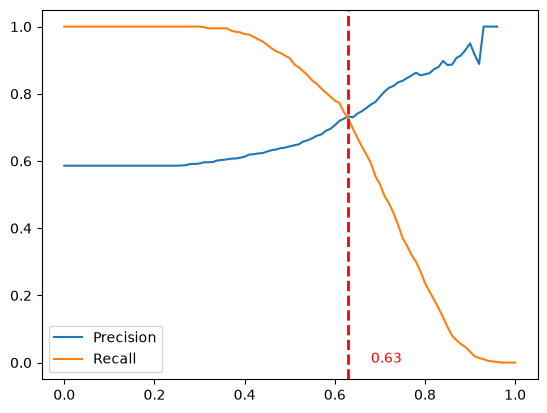

In [30]:
# Plot the precision and recall curves
plt.plot(df_scores['threshold'], df_scores['precision'], label='Precision')
plt.plot(df_scores['threshold'], df_scores['recall'], label='Recall')

# Identify the threshold for minimum difference
thres_at_min_diff = df_scores['threshold'].iloc[min_idx]

plt.axvline(thres_at_min_diff, color='red', linestyle='--', linewidth=2)
plt.text(thres_at_min_diff+0.05, 0.0, f'{thres_at_min_diff}', color='red')
plt.legend()

## Question 4: F1 score

##### `Precision` and `recall` are conflicting. `F1` score - a metrics that takes into account both.

>##### Formula for computing F1:

$$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

>##### Where P is `precision` and R is `recall`.

#### At which `threshold`, `F1` is ***maximal***?

In [31]:
# Include new calculation column F1
df_scores['f1'] = 2 * df_scores['precision'] * df_scores['recall'] / (df_scores['precision'] + df_scores['recall'])

In [32]:
# Determine the index and largest value of F1
f1_max_idx = df_scores['f1'].idxmax()

print(f1_max_idx, round(abs(df_scores['f1'].iloc[f1_max_idx]), 4))

41 0.7576


In [33]:
# Double check with the df_scores
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(df_scores)

,threshold,tp,fp,fn,tn,precision,recall,diff,f1
0,0.00,586,414,0,0,0.586000,1.000000,-0.414000,0.738966
1,0.01,586,414,0,0,0.586000,1.000000,-0.414000,0.738966
2,0.02,586,414,0,0,0.586000,1.000000,-0.414000,0.738966
3,0.03,586,414,0,0,0.586000,1.000000,-0.414000,0.738966
4,0.04,586,414,0,0,0.586000,1.000000,-0.414000,0.738966
5,0.05,586,414,0,0,0.586000,1.000000,-0.414000,0.738966
6,0.06,586,414,0,0,0.586000,1.000000,-0.414000,0.738966
7,0.07,586,414,0,0,0.586000,1.000000,-0.414000,0.738966
8,0.08,586,414,0,0,0.586000,1.000000,-0.414000,0.738966
9,0.09,586,414,0,0,0.586000,1.000000,-0.414000,0.738966


In [34]:
# Identify the threshold at maximum of F1
thres_at_f1_max = df_scores['threshold'].iloc[f1_max_idx]

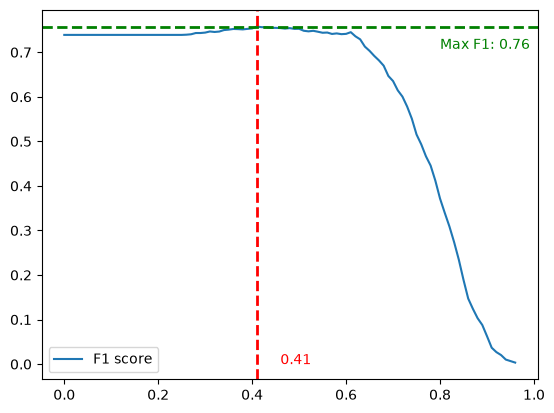

In [35]:
# Plot the graph of F1 against threshold
plt.plot(df_scores['threshold'], df_scores['f1'], label='F1 score')

f1_max = df_scores['f1'].max()
thres_at_f1_max = df_scores['threshold'].iloc[f1_max_idx]

plt.axhline(f1_max, color='green', linestyle='--', linewidth=2)
plt.text(0.8, f1_max-0.05, f'Max F1: {df_scores['f1'].max():.2f}', color='green')

plt.axvline(thres_at_f1_max, color='red', linestyle='--', linewidth=2)
plt.text(thres_at_f1_max+0.05, 0.0, f'{thres_at_f1_max:.2f}', color='red')
plt.legend()

## Question 5: 5-Fold CV

##### Evaluate the model on 5 different folds:
>##### `KFold(n_splits=5, shuffle=True, random_state=1)`
>##### 1. Iterate over different folds of `df_full_train`.
>##### 2. Split the data into train and validation.
>##### 3. Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`.
>##### 4. Use AUC to evaluate the model on validation`

#### How ***large*** is `standard deviation` of the `scores` across different folds?

In [36]:
# Train function for each fold
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [37]:
# Predict function for each fold
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [38]:
# Compute the Kfold ROC AUC score for the dataset
n_splits = 5
kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['converted'].to_numpy()
    y_val = df_val['converted'].to_numpy()
    
    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc_score = roc_auc_score(y_val, y_pred)
    scores.append(auc_score)

print(f'The average ROC AUC score is \n{np.mean(scores):.3f} \u00b1 {np.std(scores):.3f}')

The average ROC AUC score is 
0.732 ± 0.007


## Question 6: Hyperparameter Tuning

##### Use 5-Fold cross-validation to find the best parameter `C`
>##### 1. Iterate over the following `C` values: `[0.000001, 0.001, 1]`.
>##### 2. Initialize `KFold` with the same parameters as previously.
>##### 3. Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`.
>##### 4. Compute the `mean` and `std` `ROC AUC`.

#### Which `C` leads to the ***best*** `mean ROC AUC`?

In [39]:
# Compute the Kfold ROC AUC score to find the best value for parameter C
n_splits = 5

C_val = [0.000001, 0.001, 1]

results = []
for C in C_val:
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc_score = roc_auc_score(y_val, y_pred)
        scores.append(auc_score)

    score_mean = np.mean(scores)
    score_std = np.std(scores)
    results.append((C, score_mean, score_std))

    print(f'When C = {C}, The average ROC-AUC score is \n{score_mean:.3f} \u00b1 {score_std:.3f}')
    print()

When C = 1e-06, The average ROC-AUC score is 
0.617 ± 0.019

When C = 0.001, The average ROC-AUC score is 
0.749 ± 0.010

When C = 1, The average ROC-AUC score is 
0.732 ± 0.007



In [40]:
# Find the best value of C
highest_score = max(results, key=lambda item:item[1])[1]

for C, mean, std in results:
    if mean == highest_score:
        print(f'The highest average score is \n{score_mean:.3f} \u00b1 {score_std:.3f}')
        print(f'When C = {C}')

The highest average score is 
0.732 ± 0.007
When C = 0.001
